# Brazilian E-Commerce Public Dataset by Olist

В основе исследования лежит открытый набор реальных обезличенных коммерческих данных бразильской e-commerce платформы Olist Store за период с 2016 по 2018 год (около 100 000 заказов).

Бизнес-модель платформы

Olist работает как агрегатор, связывающий малый и средний бизнес Бразилии с крупнейшими торговыми площадками страны по единому контракту.
Жизненный цикл заказа в системе выглядит так:
1. Покупатель оформляет заказ на маркетплейсе.
2. Продавец получает уведомление о необходимости собрать и отгрузить товар.
3. Товар передаётся логистическим партнёрам Olist и доставляется напрямую покупателю.
4. После фактического вручения заказа (или наступления плановой даты доставки) покупателю отправляется анкета удовлетворённости, где он может оценить покупку и оставить текстовый отзыв.

Особенности структуры данных (важные для расчётов)

• Составные заказы: Один заказ (order_id) может включать несколько позиций товаров.

• Мульти-продавцы: Разные товары внутри одного и того же заказа могут отгружаться разными продавцами (seller_id), что важно учитывать при расчёте сроков сборки и стоимости доставки.

• Анонимизация данных: В целях конфиденциальности все упоминания реальных компаний и логистических партнёров в текстах отзывов заменены на названия великих домов из вселенной «Игры престолов».


### Данные
В основе исследования лежит реляционная база данных, состоящая из **9 связанных таблиц**, которые охватывают весь путь заказа — от оформления и оплаты до логистики и обратной связи от покупателей:

**`olist_customers_dataset.csv`** — данные о покупателях и их географии.
- `customer_id` — технический ключ покупателя, который генерируется заново под каждый конкретный заказ;
- `customer_unique_id` — постоянный уникальный идентификатор самого человека;
- `customer_zip_code_prefix` — первые 5 цифр почтового индекса покупателя;
- `customer_city` — город доставки покупателя;
- `customer_state` — штат (регион) покупателя.

**`olist_geolocation_dataset.csv`** — справочник географических координат по почтовым индексам Бразилии.
- `geolocation_zip_code_prefix` — первые 5 цифр почтового индекса;
- `geolocation_lat` — географическая широта;
- `geolocation_lng` — географическая долгота;
- `geolocation_city` — название города;
- `geolocation_state` — штат (регион).

**`olist_orders_dataset.csv`** — центральная таблица заказов, содержащая статусы и ключевые временные метки на каждом этапе цепочки поставки.
- `order_id` — уникальный идентификатор заказа;
- `customer_id` — идентификатор покупателя под конкретный заказ;
- `order_status` — текущий статус заказа (`delivered`, `invoiced`, `shipped`, `processing`, `unavailable`, `canceled`, `created`, `approved`);
- `order_purchase_timestamp` — дата и время оформления заказа покупателем;
- `order_approved_at` — дата и время подтверждения оплаты заказа;
- `order_delivered_carrier_date` — дата и время фактической передачи заказа продавцом в службу доставки;
- `order_delivered_customer_date` — дата и время фактического вручения заказа покупателю;
- `order_estimated_delivery_date` — плановая дата доставки.

**`olist_order_items_dataset.csv`** — детализация состава каждого заказа.
- `order_id` — уникальный идентификатор заказа;
- `order_item_id` — порядковый номер товарной позиции внутри одного заказа;
- `product_id` — уникальный идентификатор товара;
- `seller_id` — уникальный идентификатор продавца;
- `shipping_limit_date` — крайний срок, до которого продавец обязан передать товар в логистическую службу;
- `price` — цена за единицу товара;
- `freight_value` — стоимость доставки данной товарной позиции.

**`olist_order_payments_dataset.csv`** — данные об оплате заказов и транзакциях.
- `order_id` — уникальный идентификатор заказа;
- `payment_sequential` — порядковый номер платежа в рамках одного заказа;
- `payment_type` — выбранный способ оплаты (`credit_card`, `boleto`, `voucher`, `debit_card`, `not_defined`);
- `payment_installments` — количество платежей (месяцев рассрочки), выбранное покупателем;
- `payment_value` — сумма конкретной транзакции (в бразильских реалах).

**`olist_order_reviews_dataset.csv`** — данные об оценках и отзывах покупателей.
- `review_id` — уникальный идентификатор отзыва;
- `order_id` — уникальный идентификатор заказа, к которому оставлен отзыв;
- `review_score` — оценка удовлетворённости покупателя по шкале от 1 до 5;
- `review_comment_title` — заголовок текстового отзыва;
- `review_comment_message` — основной текст комментария покупателя;
- `review_creation_date` — дата отправки покупателю анкеты для оценки заказа;
- `review_answer_timestamp` — дата и время фактического заполнения отзыва покупателем.

**`olist_products_dataset.csv`** — каталог товаров с характеристиками карточек и массогабаритными параметрами.
- `product_id` — уникальный идентификатор товара;
- `product_category_name` — название категории товара на португальском языке;
- `product_name_lenght` — количество символов в названии товара;
- `product_description_lenght` — количество символов в описании карточки товара;
- `product_photos_qty` — количество опубликованных фотографий товара в карточке;
- `product_weight_g` — вес товара в граммах;
- `product_length_cm` — длина упаковки товара в сантиметрах;
- `product_height_cm` — высота упаковки товара в сантиметрах;
- `product_width_cm` — ширина упаковки товара в сантиметрах.

**`olist_sellers_dataset.csv`** — справочник продавцов, реализующих товары на платформе Olist, с информацией об их местоположении.
- `seller_id` — уникальный идентификатор продавца;
- `seller_zip_code_prefix` — первые 5 цифр почтового индекса склада или офиса продавца;
- `seller_city` — город нахождения продавца;
- `seller_state` — штат (регион) продавца.

**`product_category_name_translation.csv`** — вспомогательный справочник перевода названий товарных категорий.
- `product_category_name` — исходное название категории товара на португальском языке;
- `product_category_name_english` — перевод названия категории на английский язык.


## Знакомство с данными и предобработка

In [44]:
# импортируем библиотеки
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

In [2]:
# Создадим список с названиями таблиц
tables = ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv',  'olist_orders_dataset.csv' , 'olist_order_items_dataset.csv',
'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']
# Создадим список с названием датафреймов
dframes_name = [name.replace('olist_','').replace('_dataset.csv','').replace('.csv','') for name in tables]
# Запишем данные из таблиц в датафреймы
for i in range(len(dframes_name)):
    globals()[dframes_name[i]] = pd.read_csv(f'project/{tables[i]}')                                                                                                           

In [3]:
# Напишем функцию, которая описывает датафреймы
def describe_dataframe(df,name):
    # Считаем количество столбцов и строк
    col, row = df.shape[1], df.shape[0]
    # Считаем количество дубликатов
    dupl = df.duplicated().sum()
    print(f'=== Датафрейм {name} | Строк: {row} | Столбцы: {col} | Дубликаты: {dupl} ===')
    # Смотрим типы данных
    print('Типы данных:')
    for dtype, col in df.dtypes.groupby(df.dtypes):
        print(f'{dtype} -', end = ' ')
        print(*col.index, sep= ', ')
    # Проверяем пропуски
    nulls = df.isna().sum()
    if nulls.sum() == 0:
        print(f'Пропусков нет\n')
    else:
        print('Пропуски (%):')
        df_nulls = round(df.isna().mean()*100,2)
        display(df_nulls[df_nulls > 0])
    display(df.head())
    print('-'*70)
    print()

for name in dframes_name:
    describe_dataframe(globals()[name], name)

=== Датафрейм customers | Строк: 99441 | Столбцы: 5 | Дубликаты: 0 ===
Типы данных:
int64 - customer_zip_code_prefix
object - customer_id, customer_unique_id, customer_city, customer_state
Пропусков нет



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


----------------------------------------------------------------------

=== Датафрейм geolocation | Строк: 1000163 | Столбцы: 5 | Дубликаты: 261831 ===
Типы данных:
int64 - geolocation_zip_code_prefix
float64 - geolocation_lat, geolocation_lng
object - geolocation_city, geolocation_state
Пропусков нет



,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


----------------------------------------------------------------------

=== Датафрейм orders | Строк: 99441 | Столбцы: 8 | Дубликаты: 0 ===
Типы данных:
object - order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date
Пропуски (%):


order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
dtype: float64

... (12 outputs left out)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


----------------------------------------------------------------------

=== Датафрейм product_category_name_translation | Строк: 71 | Столбцы: 2 | Дубликаты: 0 ===
Типы данных:
object - product_category_name, product_category_name_english
Пропусков нет



,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


----------------------------------------------------------------------



После поверхостной проверки 9 датафреймов мы выяснили, что:

**Дубликаты**:
были найдены в датафрейме `geolocation` (26% | 261 831 строк)

**Пропуски**: В трех датафреймах были найдены пропуски.
- `orders` незначительное количество пропусков в 3 столбцах из 8 (`order_approved_at` 0.16%, `order_delivered_carrier_date` 1.79 %, `order_delivered_customer_date` 2.98%). Оставляем пропуски без изменений. Заполнять даты искусственно (медианой или заглушкой) нельзя, так как пропуск здесь означает, что заказ ещё не дошёл до этого этапа или был отменён.
- `order_reviews` большое количество пропусков в 2 столбцах из 7 (`review_comment_title` 88.34%, `review_comment_message` 58.70%). Оставляем пропуски. Покупатели обязаны поставить оценку `review_score`, но текстовый отзыв пишут по желанию. 
- `products` незначительное количество пропусков в 8 столбцах из 9 (`product_category_name` 1.85%, `product_name_lenght` 1.85%, 
`product_description_lenght` 1.85%, `product_photos_qty` 1.85%, `product_weight_g` 0.01%, `product_length_cm` 0.01%, `product_height_cm` 0.01%, `product_width_cm` 0.01%). Заменим пропуски в столбце `product_category_name` на `unknown`. Остальные пропуски оставим без изменений.

In [21]:
# Заменим пропуски в колонке product_category_name на unknown
products['product_category_name'] = products['product_category_name'].fillna('unknown')

In [4]:
# Найдем в датафреймах все колонки, которые можно привести к типу datetime64 и сделаем преобразование
def find_timedate_column(df, name):
    datetime_col_list = []
    date_pattern = r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$'
    #print(name)
    #display(df.head())
    for col in df.select_dtypes(include = 'object').columns:
        value = df[col].dropna().astype(str)
        if value.str.match(date_pattern).mean() == 1:
            datetime_col_list.append(col)
            df[col] = pd.to_datetime(df[col])
    if len(datetime_col_list) > 0:
        print(f'Датафрейм: {name} | Переведены в datetime:', end = ' ')
        print(*datetime_col_list, sep = ',')
            
for name_df in dframes_name:
    find_timedate_column(globals()[name_df], name_df)

Датафрейм: orders | Переведены в datetime: order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
Датафрейм: order_items | Переведены в datetime: shipping_limit_date
Датафрейм: order_reviews | Переведены в datetime: review_creation_date,review_answer_timestamp


In [5]:
# Найдем в датафреймах все колонки, которые можно привести к типу Int и сделаем преобразование
def find_int_column(df, name):
    converted_list = []
    for col in df.select_dtypes(include = 'float64').columns:
        value = df[col].dropna()
        if (value % 1 == 0).all():
            max_size = value.max()
            if max_size <= 127:
                dtype = 'Int8'
            elif max_size <= 32767:
                dtype = 'Int16'
            elif max_size <= 2147483647:
                dtype = 'Int32'
            else:
                dtype = 'Int64'
            df[col] = df[col].astype(dtype)
            converted_list.append(f'{col}({dtype})')
    if converted_list:
        print(f"Датафрейм: {name} | Преобразованы: {', '.join(converted_list)}")
           
for name_df in dframes_name:
    find_int_column(globals()[name_df], name_df)

Датафрейм: products | Преобразованы: product_name_lenght(Int8), product_description_lenght(Int16), product_photos_qty(Int8), product_weight_g(Int32), product_length_cm(Int8), product_height_cm(Int8), product_width_cm(Int8)


Мы также можем дополнительно оптимизировать потребление памяти, понизив разрядность целочисленных столбцов с int64 до более компактных типов (int8, int16, int32) там, где это позволяет диапазон значений (за исключением ключевых полей с почтовыми индексами zip_code_prefix).

In [6]:
# Найдем в датафреймах все колонки типа int64, в которых можно понизить разрядность
def optim_int_column(df, name):
    regex = r'_zip_code_prefix'
    convert_col = []
    for col in df.select_dtypes(include = 'int64').columns:
        if not re.search(regex, col):
            max_size = df[col].max()
            if max_size <= 127:
                dtype = 'int8'
            elif max_size <= 32767:
                dtype = 'int16'
            elif max_size <= 2147483647:
                dtype = 'int32'
            else:
                dtype = 'int64'
            if dtype != 'int64':
                convert_col.append(f'{col}({dtype})')
                df[col] = df[col].astype(dtype)
    if convert_col:
        print(f'Датафрейм: {name} | Преобразованы {', '.join(convert_col)}')
                

for name_df in dframes_name:
    optim_int_column(globals()[name_df], name_df)

Датафрейм: order_items | Преобразованы order_item_id(int8)
Датафрейм: order_payments | Преобразованы payment_sequential(int8), payment_installments(int8)
Датафрейм: order_reviews | Преобразованы review_score(int8)


In [7]:
# Удалим полнные дубликаты из датафрейма geolocation
geolocation.drop_duplicates(inplace = True)

## Исследовательский анализ данных EDA

### 1.	География спроса и предложения:
Проверим распределение покупателей и продавцов по штатам и городам. И составим топ-5 штатов-лидеров по объёму заказов и концентрации складов.


Сначала оценим географический охват маркетплейса — посмотрим на распределение количества уникальных городов с покупателями по штатам, чтобы выявить регионы с самой широкой сетью доставки.

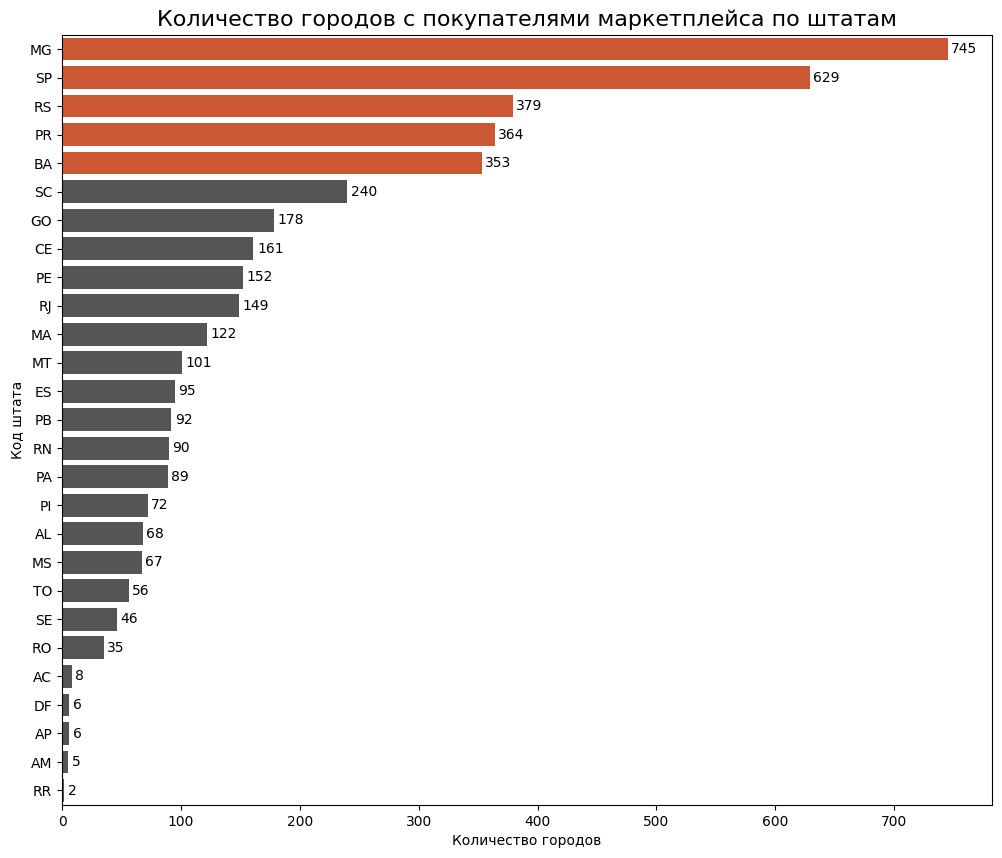

In [84]:
colors = ['#E64A19'] * 5 + ['#555555'] * 22
cities_per_state = (customers.groupby(['customer_state'])['customer_city'].nunique()
                            .reset_index()
                            .rename(columns = {'customer_city': 'unique_cities'})
                            .sort_values('unique_cities', ascending = False)
                            .reset_index(drop = True))

plt.figure(figsize = (12,10))
ax = sns.barplot(data = cities_per_state, 
            x = 'unique_cities', 
            y = 'customer_state',
            hue = 'customer_state',
            palette= colors)
for p in ax.patches:
    width = p.get_width()
    y_center = p.get_y() + p.get_height() / 2
    ax.text( width+ 3,
             y_center,
             f'{width:.0f}',
             ha = 'left',
             va = 'center',
             color = 'black',
             fontsize = 10)

plt.title('Количество городов с покупателями маркетплейса по штатам', fontsize = 16)
plt.xlabel('Количество городов')
plt.ylabel('Код штата')
plt.show()

Лидеры по числу городов (MG — 745, SP — 629, RS — 379, PR — 364, BA — 353): Это крупные штаты с разветвлённой сетью муниципалитетов. 

Северные и труднодоступные штаты внизу списка (RR — 2 города, AM — 5, AP — 6, AC — 8): Это отдаленные северные (амазонские) штаты с низкой плотностью населения и труднодоступной инфраструктурой.

Далее оценим распределение уникальных покупателей по штатам, чтобы сравнить широту географического охвата с реальной концентрацией клиентской базы.

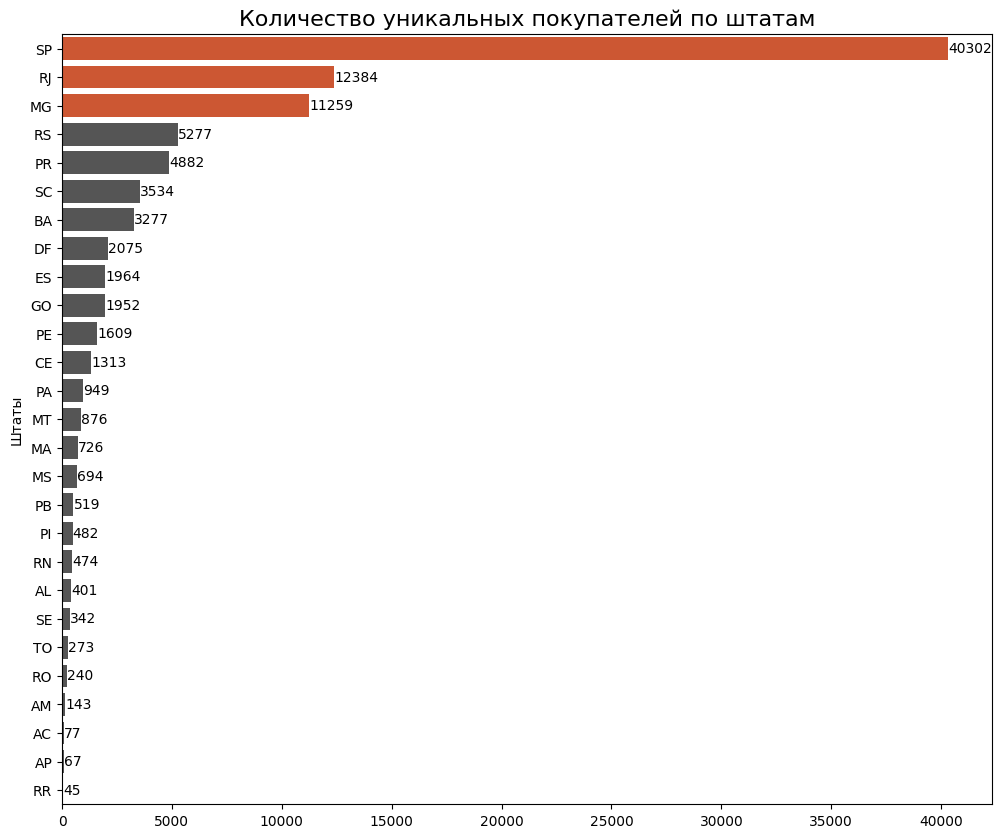

In [116]:
colors = ['#E64A19'] * 3 + ['#555555'] * 24
customers_state = (customers.groupby(['customer_state'])['customer_unique_id'].nunique()
                   .reset_index()
                   .rename(columns = {'customer_unique_id':'count_customers'})
                   .sort_values('count_customers', ascending = False)
                   .reset_index(drop=True))
customers_state
plt.figure(figsize = (12,10))
ax = sns.barplot(data = customers_state, 
            x = 'count_customers', 
            y = 'customer_state',
            hue = 'customer_state',
            palette = colors)
for p in ax.patches:
    width = p.get_width()
    y_center = p.get_y() +p.get_height() / 2 
    ax.text(width + 5,
           y_center,
           f'{width:.0f}',
           ha = 'left',
           va = 'center', 
           color = 'black',
           fontsize = 10
           )
plt.title('Количество уникальных покупателей по штатам', fontsize = 16)
plt.ylabel('Штаты')
plt.xlabel('')
plt.show()

По количеству уникальных покупателей с большим отрывом лидирует штат Сан-Паулу (SP) — 40 302 человека (около 42% всей клиентской базы). Второе место занимает Рио-де-Жанейро (RJ) (12 384 покупателя, ~13%), несмотря на то что по числу охваченных городов он находится лишь на 10-й строчке (149 городов) — это объясняется высокой плотностью населения и концентрацией спроса в мегаполисе. В отдалённых и труднодоступных северных регионах страны (штаты Амазонии) доля покупателей остаётся минимальной.

На следующем шаге определим Топ-5 городов, концентрирующих наибольшее число покупателей маркетплейса.

In [128]:
customers_cities = (customers.groupby(['customer_state','customer_city'])['customer_unique_id'].nunique()
                        .reset_index()
                        .rename(columns = {'customer_unique_id':'count_customers'})
                        .sort_values('count_customers', ascending = False)
                        .reset_index(drop=True))
top5_cities = pd.merge(customers_cities, customers_state, on = 'customer_state', how = 'left', suffixes = ('_city', '_state'))
top5_cities['share_in_state'] = round(top5_cities['count_customers_city'] / top5_cities['count_customers_state'] * 100,1)
display(top5_cities.head())

,customer_state,customer_city,count_customers_city,count_customers_state,share_in_state
0,SP,sao paulo,14984,40302,37.2
1,RJ,rio de janeiro,6620,12384,53.5
2,MG,belo horizonte,2672,11259,23.7
3,DF,brasilia,2069,2075,99.7
4,PR,curitiba,1465,4882,30.0


• Пятёрка лидеров по числу уникальных покупателей: **Сан-Паулу** (sao paulo — 14 984), **Рио-де-Жанейро** (rio de janeiro — 6 620), **Белу-Оризонти** (belo horizonte — 2 672), **Бразилиа** (brasilia — 2 069) и **Куритиба** (curitiba — 1 465). Вместе эти 5 городов формируют почти 29% всей клиентской базы маркетплейса.

• Разная концентрация спроса внутри регионов: В Федеральном округе (DF) практически весь спрос сосредоточен в столице — Бразилиа забирает 99.7% покупателей региона. В штате Рио-де-Жанейро (RJ) на административный центр приходится больше половины клиентов (53.5%). В то же время в штатах Сан-Паулу (SP) и Минас-Жерайс (MG) покупатели распределены гораздо равномернее по области: доли столиц составляют лишь 37.2% и 23.7% соответственно.

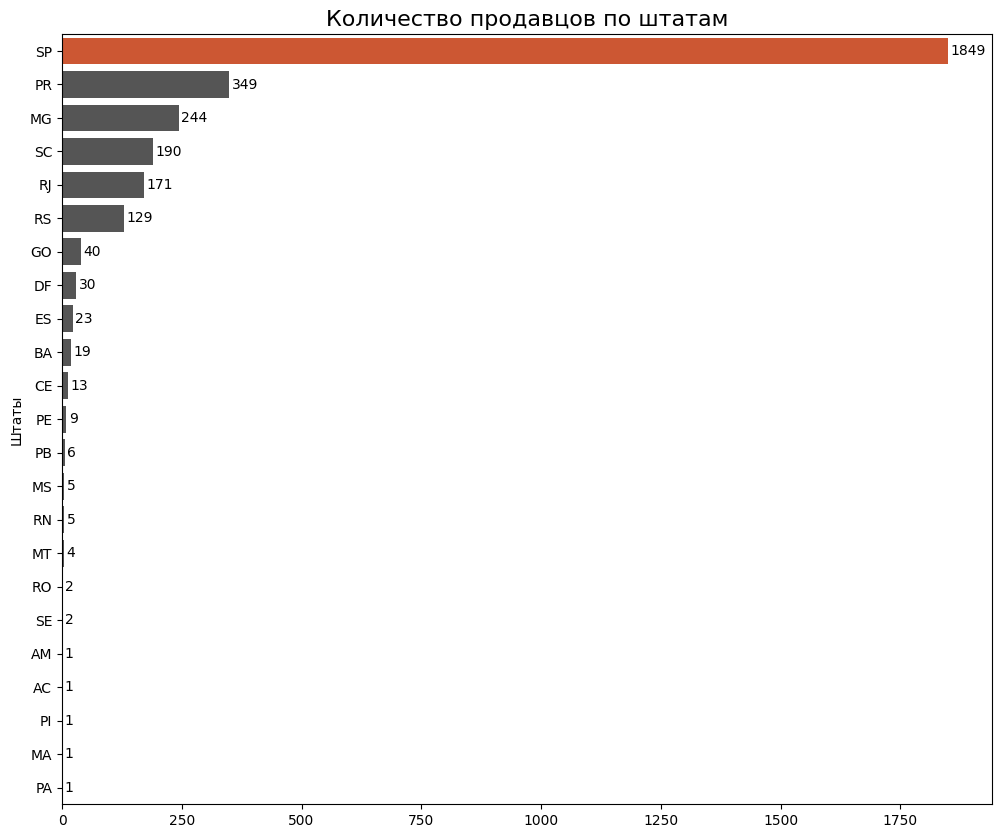

In [146]:
colors = ['#E64A19'] * 1 + ['#555555'] * 22
sellers_state = (sellers.groupby(['seller_state'])['seller_id'].nunique()
                   .reset_index()
                   .rename(columns = {'seller_id':'count_sellers'})
                   .sort_values('count_sellers', ascending = False)
                   .reset_index(drop=True))
plt.figure(figsize = (12,10))
ax = sns.barplot(data = sellers_state,
                x = 'count_sellers',
                y = 'seller_state',
                hue = 'seller_state',
                palette = colors)
for p in ax.patches:
    width = p.get_width()
    y_center = p.get_y() + p.get_height() /2
    ax.text(width +5,
           y_center,
           f'{width:.0f}',
           ha = 'left',
           va = 'center',
           color = 'black')
plt.title('Количество продавцов по штатам', fontsize = 16)
plt.xlabel('')
plt.ylabel('Штаты')
plt.show()

• Централизация предложения: в штате Сан-Паулу (SP) сосредоточено 1 849 продавцов (почти 60% от всей базы мерчантов маркетплейса).

• Дефицит локальных складов в регионах: в труднодоступных северных и северо-восточных штатах (AM, AC, PI, MA, PA) присутствует всего по 1 продавцу, из-за чего заказы в эти регионы приходится доставлять издалека.

In [159]:
# так как одному и точу же коду соответсвуют разные координаты, возбмеме медиану
geo_clean = (geolocation.groupby(['geolocation_zip_code_prefix'])
                        .agg(lat = ('geolocation_lat', 'median'), lng = ('geolocation_lng','median'))
                         .reset_index())
customers_geo = pd.merge(customers, geo_clean, left_on = 'customer_zip_code_prefix', right_on = 'geolocation_zip_code_prefix')
customers_geo.drop_duplicates('customer_unique_id', inplace = True)
sellers_geo = pd.merge(sellers, geo_clean, left_on = 'seller_zip_code_prefix', right_on = 'geolocation_zip_code_prefix')


,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,lat,lng
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,13023,-22.893863,-47.062006
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,13844,-22.382869,-46.947992
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,20031,-22.910174,-43.176775
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,4195,-23.656991,-46.612490
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,12914,-22.963763,-46.534676
...,...,...,...,...,...,...,...
3083,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR,87111,-23.448591,-51.869229
3084,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC,88137,-27.626905,-48.674389
3085,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP,4650,-23.657622,-46.677126
3086,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS,96080,-31.751451,-52.323078


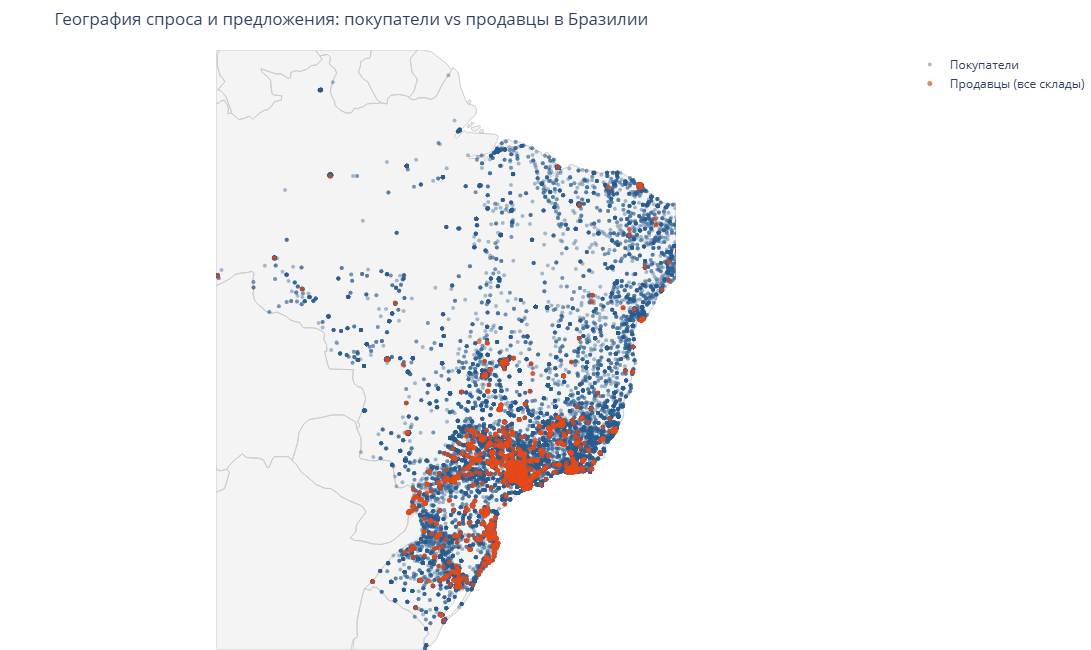

In [165]:
fig = go.Figure()

# Слой покупателей (синие полупрозрачные точки)
fig.add_trace(go.Scattergeo(
    lon=customers_geo['lng'],
    lat=customers_geo['lat'],
    mode='markers',
    name='Покупатели',
    marker=dict(size=4, color='#2B5C8F', opacity=0.4)
))

# Слой продавцов (яркие красные точки поверх)
fig.add_trace(go.Scattergeo(
    lon=sellers_geo['lng'],
    lat=sellers_geo['lat'],
    mode='markers',
    name='Продавцы (все склады)',
    marker=dict(size=5, color='#E64A19', opacity=0.7)
))

fig.update_geos(
    scope='south america',
    center=dict(lat=-15, lon=-52),
    projection_scale=2.2,
    showland=True, landcolor='#F4F4F4',
    showcountries=True, countrycolor='#CCCCCC',
    showsubunits=True, subunitcolor='#E0E0E0'
)

fig.update_layout(
    title='География спроса и предложения: покупатели vs продавцы в Бразилии',
    height=650,
    margin=dict(l=0, r=0, t=50, b=0)
)
fig.show()